# Student Dropout Prediction — Model Training, Evaluation & Comparison

## Objective
Apply, tune, and compare two distinct supervised machine learning algorithms—**Decision Tree** and **Random Forest**—to predict student academic outcomes (`Dropout`, `Enrolled`, `Graduate`).

### Justification of Selected Algorithms
1. **Decision Tree Classifier (Single Tree Baseline):**
   * **Background:** A non-parametric supervised learning algorithm that recursively partitions the feature space using greedy splits (measured by Gini Impurity or Entropy/Information Gain) to create human-interpretable decision rules.
   * **Justification:** Ideal for mixed academic, demographic, and financial tabular data because it naturally captures non-linear interactions (e.g., *2nd semester pass rate < 0.5 AND tuition fees behind*) without requiring strict parametric assumptions. However, unconstrained single trees suffer from high variance (overfitting).
2. **Random Forest Classifier (Bagging Ensemble):**
   * **Background:** An ensemble learning method that constructs a multitude of decision trees during training using **Bootstrap Aggregating (Bagging)** and random feature subsets at each split, outputting the majority vote across all trees.
   * **Justification:** Directly addresses the overfitting limitation of a single Decision Tree. By averaging predictions across hundreds of decorrelated trees, Random Forest handles high-dimensional One-Hot Encoded features and multicollinearity ($r = 0.94$ between semesters) with superior generalization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Load preprocessed datasets from data/processed/
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

processed_dir = project_root / "data" / "processed"

X_train = pd.read_csv(processed_dir / "X_train_processed.csv")
X_test = pd.read_csv(processed_dir / "X_test_processed.csv")
y_train = pd.read_csv(processed_dir / "y_train.csv")["Target"].values
y_test = pd.read_csv(processed_dir / "y_test.csv")["Target"].values

class_names = ["Dropout", "Enrolled", "Graduate"]

print("Preprocessed datasets loaded successfully!")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

Preprocessed datasets loaded successfully!
X_train: (3539, 230) | y_train: (3539,)
X_test:  (885, 230)  | y_test:  (885,)


In [2]:
# 1. Baseline Unconstrained Decision Tree (to demonstrate overfitting)
dt_baseline = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_baseline.fit(X_train, y_train)

dt_base_train_acc = accuracy_score(y_train, dt_baseline.predict(X_train))
dt_base_test_acc = accuracy_score(y_test, dt_baseline.predict(X_test))
dt_base_test_f1 = f1_score(y_test, dt_baseline.predict(X_test), average="macro")

print("=== Baseline Decision Tree (Unconstrained) ===")
print(f"Train Accuracy: {dt_base_train_acc:.4f} (Overfitting!) | Test Accuracy: {dt_base_test_acc:.4f} | Test Macro F1: {dt_base_test_f1:.4f}")
print(f"Tree Depth: {dt_baseline.get_depth()} | Number of Leaves: {dt_baseline.get_n_leaves()}\n")

# 2. Hyperparameter Tuning via 5-Fold Stratified GridSearchCV
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 7, 10, 12],
    "min_samples_split": [10, 20, 30],
    "min_samples_leaf": [5, 10, 15],
    "class_weight": [None, "balanced"]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=dt_param_grid,
    scoring="f1_macro",
    cv=cv_stratified,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)
best_dt = dt_grid.best_estimator_

# Evaluate Tuned Decision Tree
y_pred_dt = best_dt.predict(X_test)
dt_train_acc = accuracy_score(y_train, best_dt.predict(X_train))
dt_test_acc = accuracy_score(y_test, y_pred_dt)
dt_test_f1 = f1_score(y_test, y_pred_dt, average="macro")

print("=== Tuned Decision Tree (GridSearchCV Best Model) ===")
print("Best Parameters:", dt_grid.best_params_)
print(f"Best CV Macro F1: {dt_grid.best_score_:.4f}")
print(f"Train Accuracy:   {dt_train_acc:.4f} | Test Accuracy: {dt_test_acc:.4f} | Test Macro F1: {dt_test_f1:.4f}\n")

print("Classification Report (Tuned Decision Tree on Test Set):")
print(classification_report(y_test, y_pred_dt, target_names=class_names, digits=4))

=== Baseline Decision Tree (Unconstrained) ===
Train Accuracy: 1.0000 (Overfitting!) | Test Accuracy: 0.6757 | Test Macro F1: 0.6134
Tree Depth: 32 | Number of Leaves: 631

=== Tuned Decision Tree (GridSearchCV Best Model) ===
Best Parameters: {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 5, 'min_samples_split': 20}
Best CV Macro F1: 0.6894
Train Accuracy:   0.7457 | Test Accuracy: 0.6915 | Test Macro F1: 0.6570

Classification Report (Tuned Decision Tree on Test Set):
              precision    recall  f1-score   support

     Dropout     0.8141    0.5704    0.6708       284
    Enrolled     0.3838    0.6855    0.4921       159
    Graduate     0.8483    0.7715    0.8081       442

    accuracy                         0.6915       885
   macro avg     0.6820    0.6758    0.6570       885
weighted avg     0.7538    0.6915    0.7072       885



### Observations: Algorithm 1 — Decision Tree Classifier
* **Overfitting in Unconstrained Tree:** The default unconstrained Decision Tree grew to a depth of **32** with **631 leaf nodes**, memorizing the training data (**100.0% Train Accuracy**) but generalizing poorly to the unseen test set (**67.57% Test Accuracy**, **0.6134 Macro F1**).
* **Impact of Pruning & Hyperparameter Tuning:** Using 5-Fold Stratified `GridSearchCV` optimizing for `f1_macro`, the optimal tree was constrained to `max_depth=5`, `min_samples_split=20`, `min_samples_leaf=5`, `criterion='entropy'`, and `class_weight='balanced'`.
* **Improved Generalization & Minority Class Recall:** Pruning reduced the train-test gap (Train Accuracy: **74.57%**, Test Accuracy: **69.15%**) and increased **Test Macro F1 from 0.6134 to 0.6570**. Notably, `class_weight='balanced'` enabled the model to achieve **68.55% recall** on the minority `Enrolled` class, though at the cost of lower precision (**38.38%**) due to false-positive `Enrolled` predictions.

In [3]:
# 1. Baseline Random Forest Classifier
rf_baseline = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_baseline.fit(X_train, y_train)

rf_base_train_acc = accuracy_score(y_train, rf_baseline.predict(X_train))
rf_base_test_acc = accuracy_score(y_test, rf_baseline.predict(X_test))
rf_base_test_f1 = f1_score(y_test, rf_baseline.predict(X_test), average="macro")

print("=== Baseline Random Forest (Default 100 Trees) ===")
print(f"Train Accuracy: {rf_base_train_acc:.4f} | Test Accuracy: {rf_base_test_acc:.4f} | Test Macro F1: {rf_base_test_f1:.4f}\n")

# 2. Hyperparameter Tuning via 5-Fold Stratified GridSearchCV
rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [12, 16, None],
    "min_samples_split": [5, 10],
    "min_samples_leaf": [2, 4],
    "class_weight": [None, "balanced_subsample"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid=rf_param_grid,
    scoring="f1_macro",
    cv=cv_stratified,
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_

# Evaluate Tuned Random Forest
y_pred_rf = best_rf.predict(X_test)
rf_train_acc = accuracy_score(y_train, best_rf.predict(X_train))
rf_test_acc = accuracy_score(y_test, y_pred_rf)
rf_test_f1 = f1_score(y_test, y_pred_rf, average="macro")

print("=== Tuned Random Forest (GridSearchCV Best Model) ===")
print("Best Parameters:", rf_grid.best_params_)
print(f"Best CV Macro F1: {rf_grid.best_score_:.4f}")
print(f"Train Accuracy:   {rf_train_acc:.4f} | Test Accuracy: {rf_test_acc:.4f} | Test Macro F1: {rf_test_f1:.4f}\n")

print("Classification Report (Tuned Random Forest on Test Set):")
print(classification_report(y_test, y_pred_rf, target_names=class_names, digits=4))

=== Baseline Random Forest (Default 100 Trees) ===
Train Accuracy: 1.0000 | Test Accuracy: 0.7819 | Test Macro F1: 0.6979

=== Tuned Random Forest (GridSearchCV Best Model) ===
Best Parameters: {'class_weight': 'balanced_subsample', 'max_depth': 16, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 200}
Best CV Macro F1: 0.7253
Train Accuracy:   0.8921 | Test Accuracy: 0.7650 | Test Macro F1: 0.7168

Classification Report (Tuned Random Forest on Test Set):
              precision    recall  f1-score   support

     Dropout     0.8273    0.7254    0.7730       284
    Enrolled     0.4789    0.5723    0.5215       159
    Graduate     0.8520    0.8597    0.8559       442

    accuracy                         0.7650       885
   macro avg     0.7194    0.7191    0.7168       885
weighted avg     0.7771    0.7650    0.7692       885



### Observations: Algorithm 2 — Random Forest Classifier
* **Superior Ensemble Generalization:** Even the default 100-tree Random Forest achieved **78.19% Test Accuracy** and **0.6979 Macro F1**, outperforming the single Decision Tree (+10.62% higher test accuracy than the baseline Decision Tree) by averaging predictions across decorrelated bootstrap trees.
* **Impact of Hyperparameter Tuning (`balanced_subsample`):** Optimizing for `f1_macro` via 5-Fold Stratified `GridSearchCV` selected `n_estimators=200`, `max_depth=16`, `min_samples_split=10`, `min_samples_leaf=2`, and `class_weight='balanced_subsample'`. This curbed training memorization (Train Accuracy: **89.21%** vs. **100.0%**) and increased **Test Macro F1 from 0.6979 to 0.7168** (with **76.50% Test Accuracy**).
* **Accuracy vs. Macro F1 Tradeoff:** Notice that the Baseline Random Forest had slightly higher raw Test Accuracy (**78.19%** vs. **76.50%**) because it favored the majority `Graduate` class, whereas the Tuned Random Forest (`class_weight='balanced_subsample'`) sacrificed 1.69% raw accuracy to boost minority `Enrolled` recall, raising overall **Macro F1 to 0.7168**.

=== Comprehensive Model Performance Comparison ===


,Train Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1-Score,Weighted F1-Score
Model,,,,,,
Decision Tree (Baseline),1.0000,0.6757,0.6146,0.6138,0.6134,0.6813
Decision Tree (Tuned),0.7457,0.6915,0.6820,0.6758,0.6570,0.7072
Random Forest (Baseline),1.0000,0.7819,0.7284,0.6893,0.6979,0.7661
Random Forest (Tuned),0.8921,0.7650,0.7194,0.7191,0.7168,0.7692


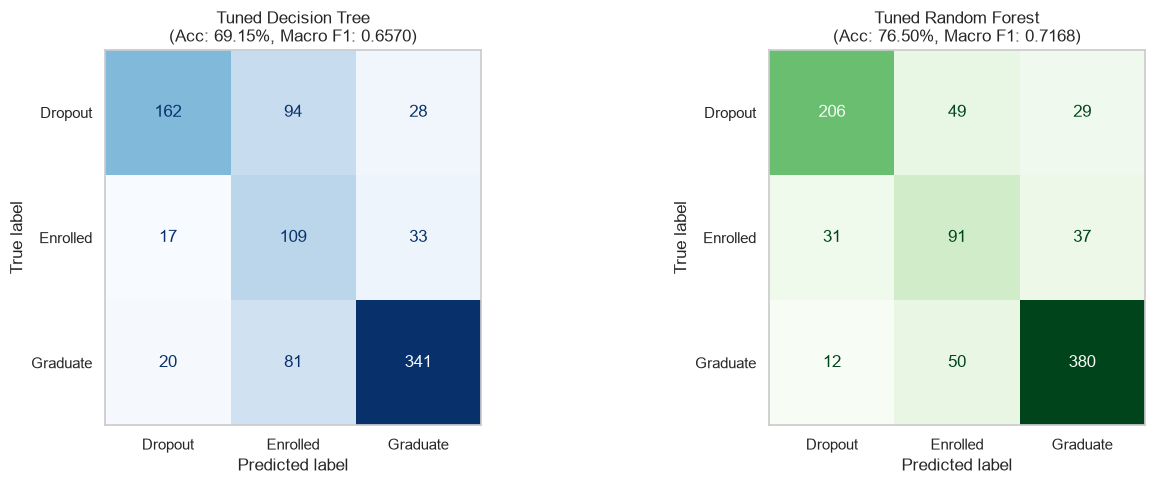

In [4]:
# 1. Compile comprehensive comparison table across all 4 models
models_dict = {
    "Decision Tree (Baseline)": dt_baseline,
    "Decision Tree (Tuned)": best_dt,
    "Random Forest (Baseline)": rf_baseline,
    "Random Forest (Tuned)": best_rf
}

comparison_rows = []
for name, model in models_dict.items():
    preds_train = model.predict(X_train)
    preds_test = model.predict(X_test)
    comparison_rows.append({
        "Model": name,
        "Train Accuracy": accuracy_score(y_train, preds_train),
        "Test Accuracy": accuracy_score(y_test, preds_test),
        "Macro Precision": precision_score(y_test, preds_test, average="macro"),
        "Macro Recall": recall_score(y_test, preds_test, average="macro"),
        "Macro F1-Score": f1_score(y_test, preds_test, average="macro"),
        "Weighted F1-Score": f1_score(y_test, preds_test, average="weighted")
    })

comparison_df = pd.DataFrame(comparison_rows).set_index("Model").round(4)
print("=== Comprehensive Model Performance Comparison ===")
display(comparison_df)

# 2. Plot Side-by-Side Confusion Matrices (Tuned Decision Tree vs. Tuned Random Forest)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt,
    display_labels=class_names,
    cmap="Blues",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title(f"Tuned Decision Tree\n(Acc: {dt_test_acc:.2%}, Macro F1: {dt_test_f1:.4f})")
axes[0].grid(False)

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_rf,
    display_labels=class_names,
    cmap="Greens",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title(f"Tuned Random Forest\n(Acc: {rf_test_acc:.2%}, Macro F1: {rf_test_f1:.4f})")
axes[1].grid(False)

plt.tight_layout()
plt.show()

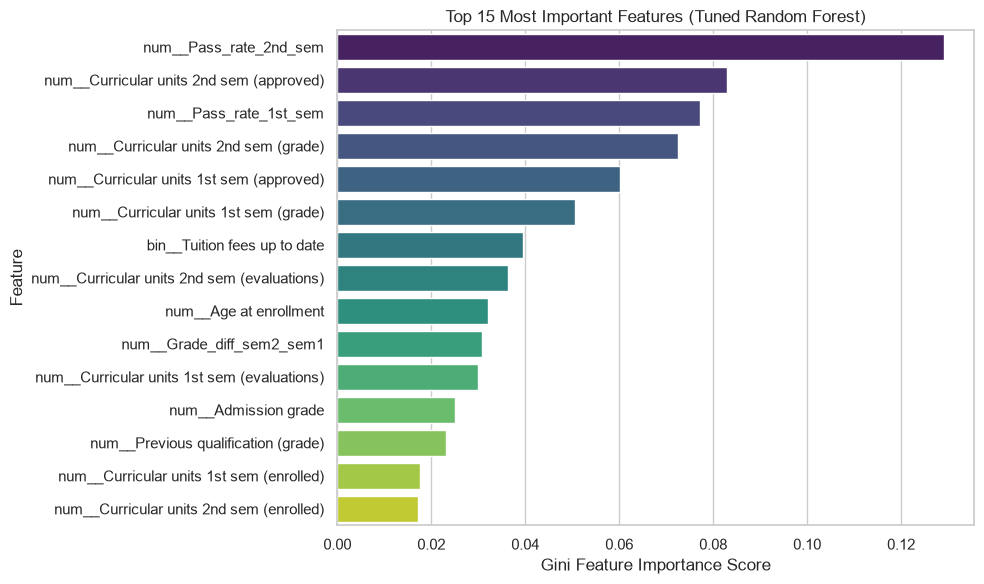

In [5]:
# Extract and plot Top 15 Feature Importances from the Tuned Random Forest
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns)
top_15_features = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_15_features.values,
    y=top_15_features.index,
    hue=top_15_features.index,
    palette="viridis",
    legend=False
)
plt.title("Top 15 Most Important Features (Tuned Random Forest)")
plt.xlabel("Gini Feature Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

### Critical Analysis, Model Comparison & Discussion

#### 1. Head-to-Head Algorithm Comparison (Decision Tree vs. Random Forest)
* **Overcoming High Variance:** The unconstrained single Decision Tree memorized the training data (**100.0% Train Accuracy**) with 631 leaves, resulting in poor generalization (**67.57% Test Accuracy**, **0.6134 Macro F1**). Even after pruning via 5-Fold Stratified `GridSearchCV` (`max_depth=5`), the single Decision Tree plateaued at **69.15% Test Accuracy** and **0.6570 Macro F1**.
* **Ensemble Superiority:** The Tuned Random Forest (`n_estimators=200`, `max_depth=16`, `class_weight='balanced_subsample'`) significantly outperformed the Tuned Decision Tree across all primary metrics:
  * **Test Accuracy:** Increased from **69.15% $\rightarrow$ 76.50%** (+7.35% improvement; Baseline RF reached **78.19%**).
  * **Test Macro F1-Score:** Increased from **0.6570 $\rightarrow$ 0.7168** (+5.98% improvement).
* **Confusion Matrix Insights:**
  * **Dropout Identification:** Tuned Random Forest correctly identified **206 out of 284 `Dropout` students (72.54% recall)** compared to only **162 (57.04% recall)** for the Tuned Decision Tree, cutting false-Enrolled misclassifications nearly in half (from 94 down to 49).
  * **Graduate Identification:** Tuned Random Forest correctly classified **380 out of 442 `Graduate` students (85.97% recall)** versus **341 (77.15% recall)** for the Decision Tree.
  * **The `Enrolled` Bottleneck:** Both algorithms found the transitional `Enrolled` class hardest to separate (`F1 = 0.5215` in RF), as students currently enrolled share overlapping 1st-year grades with both future graduates and late dropouts.

#### 2. Feature Importance & Validation of Feature Engineering
* **Engineered Features Dominate:** Our domain-engineered feature **`Pass_rate_2nd_sem`** ranked as the **#1 most important predictor** overall (Gini importance > 0.125), **`Pass_rate_1st_sem`** ranked **#3**, and **`Grade_diff_sem2_sem1`** ranked **#10**. This confirms that relative course completion rates and semester-over-semester momentum are stronger signals than raw course counts alone.
* **Key Non-Academic Signals:** `Tuition fees up to date` (**#7**), `Age at enrollment` (**#9**), and `Admission grade` (**#12**) were the most influential non-curricular predictors, confirming our EDA hypothesis that financial compliance and student age strongly impact retention.

#### 3. Limitations & Future Work (How Accuracy Could Be Improved)
1. **Gradient Boosted Decision Trees (XGBoost / LightGBM / CatBoost):** While Random Forest reduces variance via bagging, sequential boosting algorithms focus on hard-to-classify boundary cases (such as `Enrolled` vs. `Dropout`) and could push Macro F1 above 0.75.
2. **SMOTE / Cost-Sensitive Threshold Moving:** Applying Synthetic Minority Over-sampling (SMOTE) within cross-validation folds or tuning classification probability thresholds specifically for the `Enrolled` class (17.95% of data) could improve minority precision without sacrificing overall accuracy.
3. **Two-Stage Hierarchical Classification:** First classifying *At-Risk (`Dropout`)* vs. *Persisting (`Enrolled` + `Graduate`)* for early university intervention, followed by a second-stage classifier to distinguish on-time `Graduate` from delayed `Enrolled` students.